# Practice 2 — Advanced Extension

## E06 — AirPassengers ARIMA baseline và SARIMA extension

E06 là advanced extension độc lập: giữ nguyên core E01–E05, dùng AirPassengers để so sánh ARIMA baseline với SARIMA trên cùng chronological holdout.

### 1. Đọc và kiểm tra dữ liệu

In [35]:
import pandas as pd

from practice_2 import find_practice_root
from practice_2.visualization.table_style import style_table

PROJECT_ROOT = find_practice_root()
RAW_PATH = PROJECT_ROOT / "datasets" / "raw" / "airline-passengers.csv"
FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
RESULTS_DIR = PROJECT_ROOT / "outputs" / "results"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)


In [36]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(RAW_PATH)

required_columns = {"Month", "Passengers"}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(f"Missing required columns: {sorted(missing_columns)}")

df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").set_index("Month")
if df.index.has_duplicates:
    raise ValueError("AirPassengers contains duplicate timestamps.")
if not df.index.is_monotonic_increasing:
    raise ValueError("AirPassengers timestamps are not chronological.")

expected_index = pd.date_range(df.index.min(), df.index.max(), freq="MS")
missing_months = expected_index.difference(df.index)
if not missing_months.empty:
    raise ValueError(f"AirPassengers has missing monthly timestamps: {missing_months.tolist()}")

series = df["Passengers"].astype(float).asfreq("MS")
if series.isna().any():
    raise ValueError("AirPassengers contains missing passenger values.")

print(series.head())
print("Số quan sát:", len(series))
print("Giá trị thiếu:", series.isna().sum())
print("Duplicate timestamps:", series.index.duplicated().sum())
print("Frequency:", series.index.freqstr)
print("Thời gian:", series.index.min(), "đến", series.index.max())

Month
1949-01-01    112.0
1949-02-01    118.0
1949-03-01    132.0
1949-04-01    129.0
1949-05-01    121.0
Freq: MS, Name: Passengers, dtype: float64
Số quan sát: 144
Giá trị thiếu: 0
Duplicate timestamps: 0
Frequency: MS
Thời gian: 1949-01-01 00:00:00 đến 1960-12-01 00:00:00


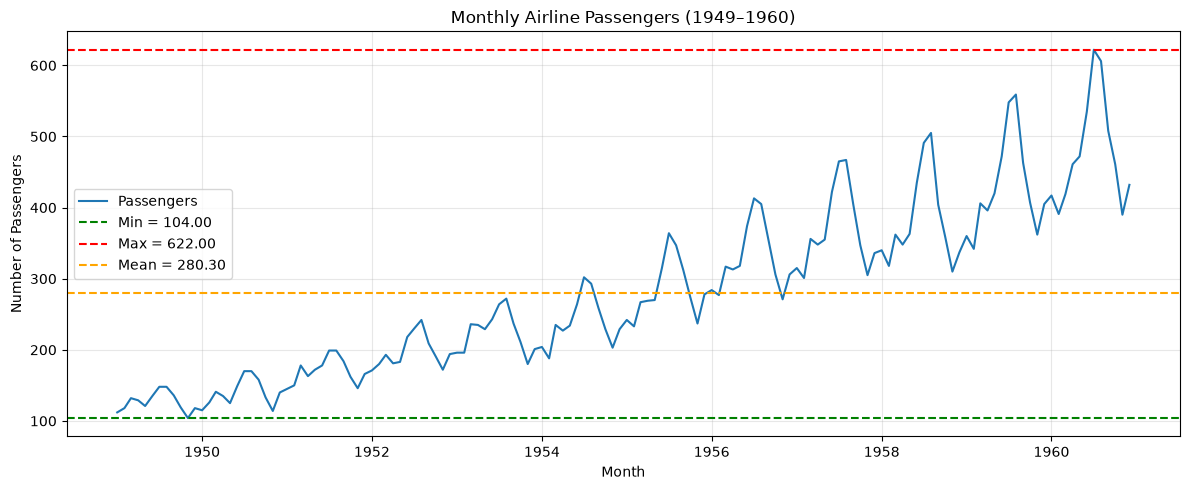

In [37]:
plt.figure(figsize=(12, 5))
# Vẽ chuỗi thời gian
plt.plot(series.index, series.values, label="Passengers")
# Tính các giá trị thống kê
min_value = series.min()
max_value = series.max()
mean_value = series.mean()
# Vẽ các đường ngang
plt.axhline(min_value, color="green", linestyle="--",
            label=f"Min = {min_value:.2f}")
plt.axhline(max_value, color="red", linestyle="--",
            label=f"Max = {max_value:.2f}")
plt.axhline(mean_value, color="orange", linestyle="--",
            label=f"Mean = {mean_value:.2f}")
plt.title("Monthly Airline Passengers (1949–1960)")
plt.xlabel("Month")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.gcf().savefig(FIGURES_DIR / "06_airpassengers_original_series.png", dpi=160, bbox_inches="tight")
plt.show()

### 2. Chronological train/test split

In [38]:
n_train = int(len(series) * 0.8)
train_series = series.iloc[:n_train]
test_series = series.iloc[n_train:]

split_summary = pd.DataFrame({
    "Partition": ["Train", "Test"],
    "Observations": [len(train_series), len(test_series)],
    "Start": [train_series.index.min(), test_series.index.min()],
    "End": [train_series.index.max(), test_series.index.max()],
    "Status": ["Training-only", "Sealed holdout"],
})

def highlight_exploratory(row):
    return ["background-color: #f1f5f9; color: #475569"] * len(row)

display(style_table(
    split_summary,
    caption="E06 — Chronological split (115 train / 29 test)",
    formats={"Observations": "{:,}", "Start": "{:%Y-%m}", "End": "{:%Y-%m}"},
    row_highlighter=highlight_exploratory,
))


Partition,Observations,Start,End,Status
Train,115,1949-01,1958-07,Training-only
Test,29,1958-08,1960-12,Sealed holdout


### 3. Stationarity on the original series

In [39]:
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(train_series.dropna(), regression="c", autolag="AIC")
adf_table = pd.DataFrame({
    "Series": ["Original training series"],
    "ADF statistic": [adf_result[0]],
    "p-value": [adf_result[1]],
    "Critical value (5%)": [adf_result[4]["5%"]],
    "Status": ["Training-only evidence"],
})
print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4]["5%"])
display(style_table(
    adf_table,
    caption="E06 — ADF on original training series",
    formats={"ADF statistic": "{:.4f}", "p-value": "{:.6f}", "Critical value (5%)": "{:.4f}"},
    row_highlighter=highlight_exploratory,
))
if adf_result[1] < 0.05:
    print("Bác bỏ H0: Có bằng chứng chuỗi dừng.")
else:
    print("Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.")


ADF Statistic: -0.35688921964045006
p-value: 0.917051728587593
Critical Values: -2.8906107514600103


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_75121/802515974.py:3: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  adf_result = adfuller(train_series.dropna(), regression="c", autolag="AIC")


Series,ADF statistic,p-value,Critical value (5%),Status
Original training series,-0.3569,0.917052,-2.8906,Training-only evidence


Chưa đủ bằng chứng bác bỏ H0: Chuỗi có thể không dừng.


### 4. Regular and seasonal differencing

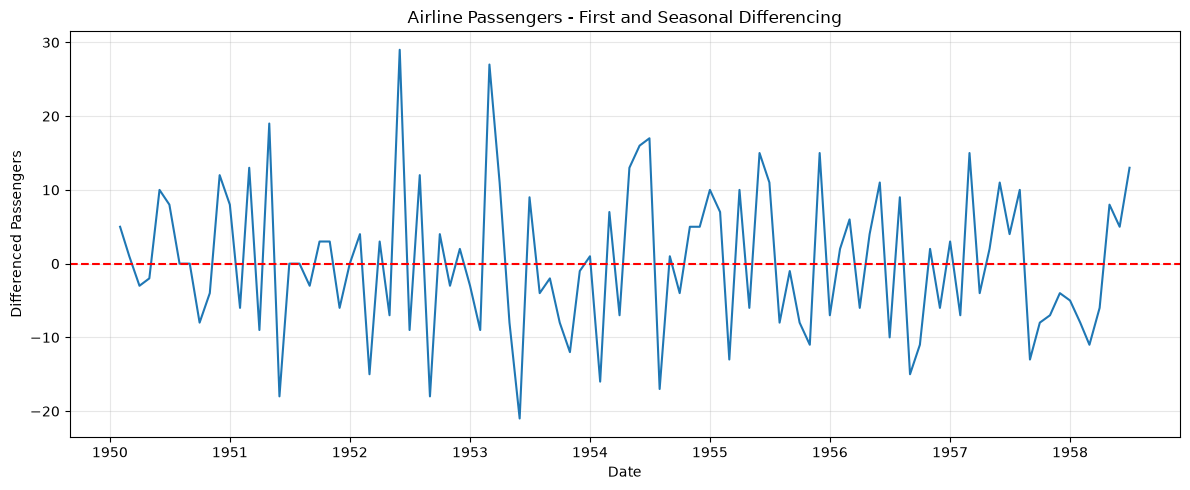

In [40]:
train_regular_diff = train_series.diff().dropna()
train_seasonal_diff = train_series.diff(12).dropna()
series_combined_diff = train_regular_diff.diff(12).dropna()

# Vẽ chuỗi sau sai phân kết hợp
plt.figure(figsize=(12, 5))
plt.plot(
    series_combined_diff.index,
    series_combined_diff.values
)
plt.axhline(0, color="red", linestyle="--")
plt.title("Airline Passengers - First and Seasonal Differencing")
plt.xlabel("Date")
plt.ylabel("Differenced Passengers")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.gcf().savefig(FIGURES_DIR / "06_airpassengers_differencing.png", dpi=160, bbox_inches="tight")
plt.show()

### 5. ADF retest after regular and seasonal differencing

In [41]:
SIGNIFICANCE_LEVEL = 0.05
differencing_inputs = {
    "Regular difference (d=1)": train_regular_diff,
    "Seasonal difference (D=1, s=12)": train_seasonal_diff,
    "Combined regular + seasonal difference": series_combined_diff,
}
adf_diff_rows = []
for series_name, transformed_series in differencing_inputs.items():
    result = adfuller(transformed_series, regression="c", autolag="AIC")
    adf_diff_rows.append({
        "Series": series_name,
        "ADF statistic": result[0],
        "p-value": result[1],
        "Critical value (5%)": result[4]["5%"],
        "Status": "Stationary evidence" if result[1] <= SIGNIFICANCE_LEVEL else "Not stationary at α=0.05",
    })

adf_diff_table = pd.DataFrame(adf_diff_rows)
display(style_table(
    adf_diff_table,
    caption="E06 — ADF after regular and seasonal differencing",
    formats={"ADF statistic": "{:.4f}", "p-value": "{:.6f}", "Critical value (5%)": "{:.4f}"},
    row_highlighter=highlight_exploratory,
))
combined_p_value = adf_diff_table.loc[
    adf_diff_table["Series"] == "Combined regular + seasonal difference", "p-value"
].iloc[0]
regular_p_value = adf_diff_table.loc[
    adf_diff_table["Series"] == "Regular difference (d=1)", "p-value"
].iloc[0]
selected_d = 1 if adf_result[1] > SIGNIFICANCE_LEVEL and combined_p_value <= SIGNIFICANCE_LEVEL else 0
selected_D = 1 if regular_p_value > SIGNIFICANCE_LEVEL and combined_p_value <= SIGNIFICANCE_LEVEL else 0
SEASONAL_PERIOD = 12
if (selected_d, selected_D) != (1, 1):
    raise RuntimeError("Training-only ADF evidence does not support the planned d=1, D=1 setup.")
print(f"Selected orders from training evidence: d={selected_d}, D={selected_D}, s={SEASONAL_PERIOD}")


/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_75121/4214030763.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(transformed_series, regression="c", autolag="AIC")
/var/folders/bk/ywq0gfcd6qv8bhfb_0y9_0000000gq/T/ipykernel_75121/4214030763.py:9: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(transformed_series, regression=

Series,ADF statistic,p-value,Critical value (5%),Status
Regular difference (d=1),-2.5396,0.106126,-2.8909,Not stationary at α=0.05
"Seasonal difference (D=1, s=12)",-3.3388,0.013231,-2.8909,Stationary evidence
Combined regular + seasonal difference,-12.1763,0.000000,-2.8906,Stationary evidence


Selected orders from training evidence: d=1, D=1, s=12


### 6. ACF/PACF on transformed training series

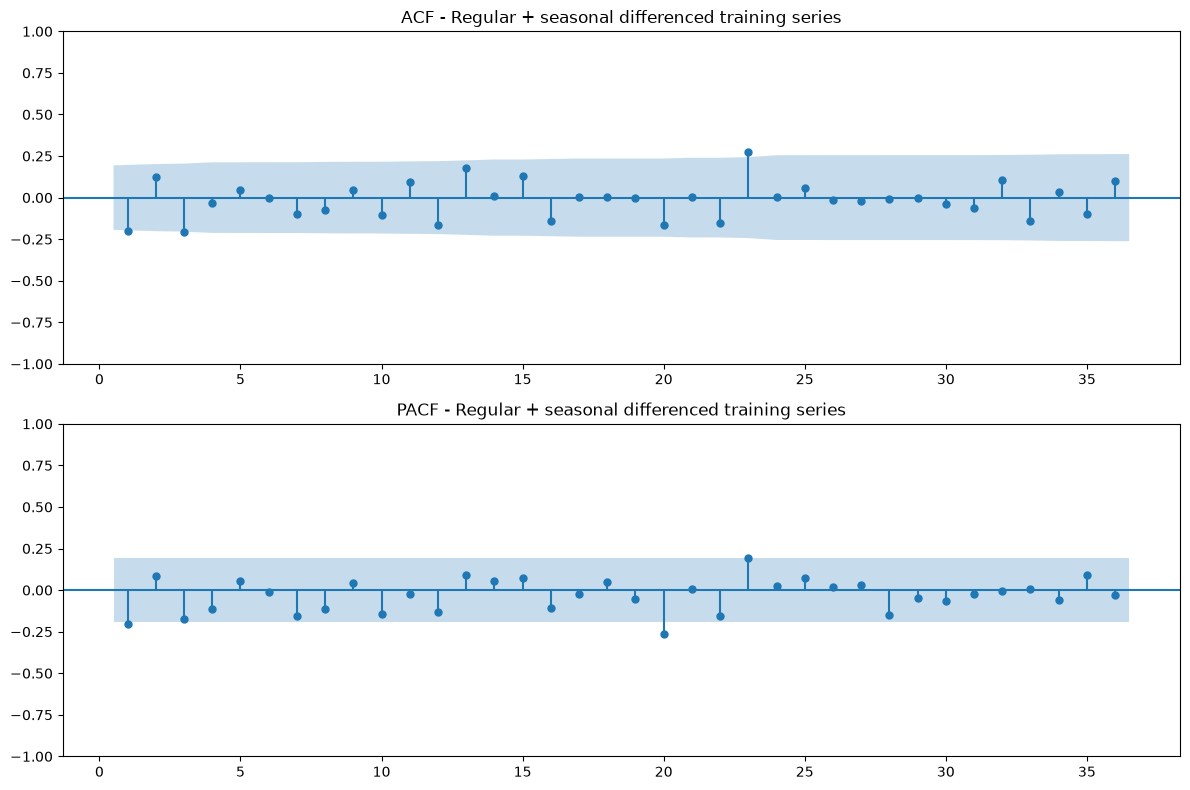

In [42]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

train_diff = train_series.diff().diff(12).dropna()

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

plot_acf(train_diff, lags=36, zero=False, ax=axes[0])
axes[0].set_title("ACF - Regular + seasonal differenced training series")

plot_pacf(
    train_diff,
    lags=36,
    zero=False,
    method="ywm",
    ax=axes[1]
)
axes[1].set_title("PACF - Regular + seasonal differenced training series")

plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_airpassengers_acf_pacf.png", dpi=160, bbox_inches="tight")
plt.show()


### Differencing decision

Regular differencing `d=1` và seasonal differencing `D=1` với `s=12` được kiểm tra trên training series. Test set không tham gia vào quyết định này.

ACF/PACF bên dưới được tính trên training series đã sai phân. Chúng chỉ dùng để đề xuất candidate orders, không tự động chứng minh candidate tốt nhất.

ARIMA baseline và SARIMA candidate bên dưới được fit trên cùng training boundary; quality chỉ được đánh giá sau residual diagnostics và forecast trên sealed holdout.

### 7. ARIMA baseline and SARIMA fitting

In [43]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import pandas as pd

model_results = {}

In [44]:
arima_baseline = SARIMAX(
    train_series,
    order=(0, selected_d, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
)

arima_result = arima_baseline.fit(disp=False)

model_results["ARIMA(0,1,1)"] = arima_result

print(arima_result.summary())

                               SARIMAX Results                                
Dep. Variable:             Passengers   No. Observations:                  115
Model:               SARIMAX(0, 1, 1)   Log Likelihood                -521.303
Date:                Fri, 27 Nov 2026   AIC                           1046.607
Time:                        11:39:51   BIC                           1052.044
Sample:                    01-01-1949   HQIC                          1048.813
                         - 07-01-1958                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1          0.4489      0.086      5.244      0.000       0.281       0.617
sigma2       645.9103    100.588      6.421      0.000     448.761     843.060
Ljung-Box (L1) (Q):                   0.64   Jarque-

In [45]:
sarima_model = SARIMAX(
    train_series,
    order=(0, selected_d, 1),
    seasonal_order=(0, selected_D, 1, SEASONAL_PERIOD),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarima_result = sarima_model.fit(disp=False)

model_results["SARIMA(0,1,1)(0,1,1,12)"] = sarima_result

print(sarima_result.summary())

                                     SARIMAX Results                                      
Dep. Variable:                         Passengers   No. Observations:                  115
Model:             SARIMAX(0, 1, 1)x(0, 1, 1, 12)   Log Likelihood                -326.671
Date:                            Fri, 27 Nov 2026   AIC                            659.342
Time:                                    11:39:51   BIC                            666.774
Sample:                                01-01-1949   HQIC                           662.336
                                     - 07-01-1958                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ma.L1         -0.1672      0.101     -1.659      0.097      -0.365       0.030
ma.S.L12      -0.1283      0.098   

In [46]:
model_comparison = pd.DataFrame({
    "Model": list(model_results.keys()),
    "AIC": [result.aic for result in model_results.values()],
    "BIC": [result.bic for result in model_results.values()],
    "Converged": [bool(result.mle_retvals.get("converged", False)) for result in model_results.values()],
    "Status": "Fit on training series only",
})
display(style_table(
    model_comparison,
    caption="E06 — ARIMA/SARIMA in-sample comparison",
    formats={"AIC": "{:.2f}", "BIC": "{:.2f}"},
    row_highlighter=highlight_exploratory,
))


Model,AIC,BIC,Converged,Status
"ARIMA(0,1,1)",1046.61,1052.04,True,Fit on training series only
"SARIMA(0,1,1)(0,1,1,12)",659.34,666.77,True,Fit on training series only


### 8. Forecast on the sealed 29-month holdout

**Biểu đồ Forecast ARIMA(0,1,1) baseline**

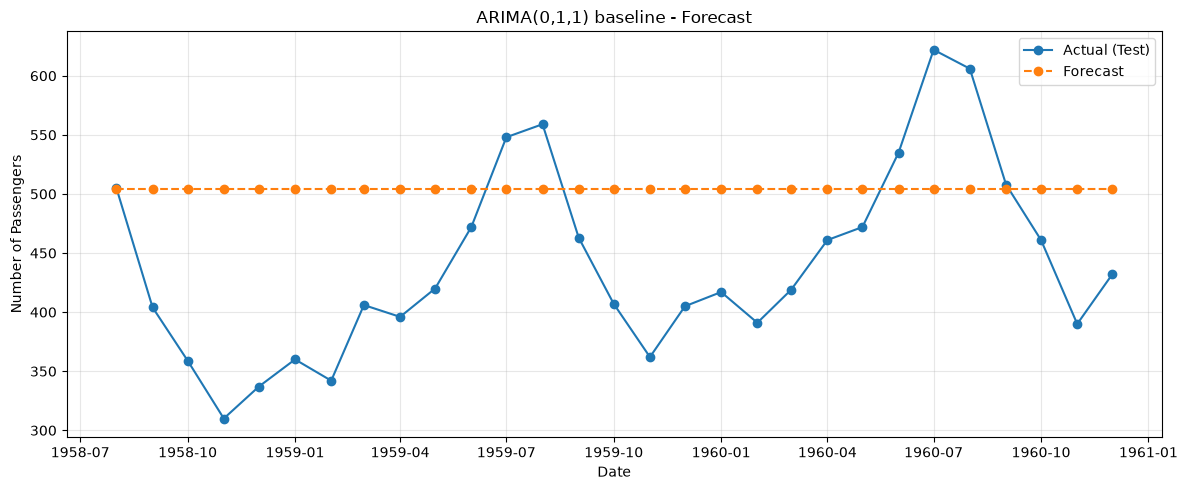

In [47]:
forecast_1 = arima_result.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_1.index,
    forecast_1.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("ARIMA(0,1,1) baseline - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.gcf().savefig(FIGURES_DIR / "06_airpassengers_forecast_arima.png", dpi=160, bbox_inches="tight")
plt.show()


**Biểu đồ Forecast SARIMA(0,1,1)(0,1,1,12)**

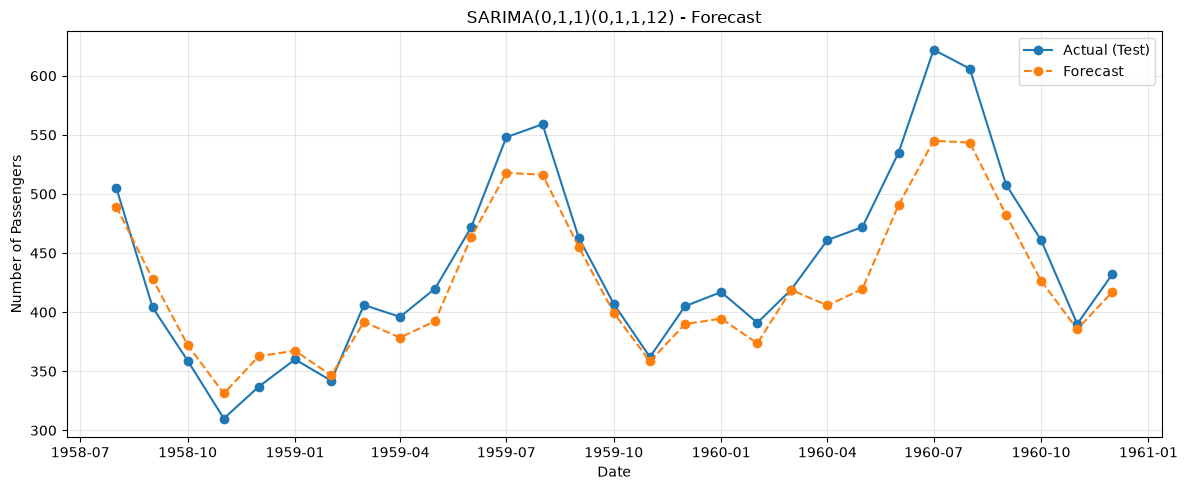

In [48]:
forecast_2 = sarima_result.forecast(steps=len(test_series))
plt.figure(figsize=(12, 5))

# Dữ liệu thực tế trên tập Test
plt.plot(
    test_series.index,
    test_series.values,
    label="Actual (Test)",
    marker="o"
)

# Giá trị dự báo
plt.plot(
    forecast_2.index,
    forecast_2.values,
    label="Forecast",
    linestyle="--",
    marker="o"
)

plt.title("SARIMA(0,1,1)(0,1,1,12) - Forecast")
plt.xlabel("Date")
plt.ylabel("Number of Passengers")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.gcf().savefig(FIGURES_DIR / "06_airpassengers_forecast_sarima.png", dpi=160, bbox_inches="tight")
plt.show()

### 9. Holdout metrics and model comparison

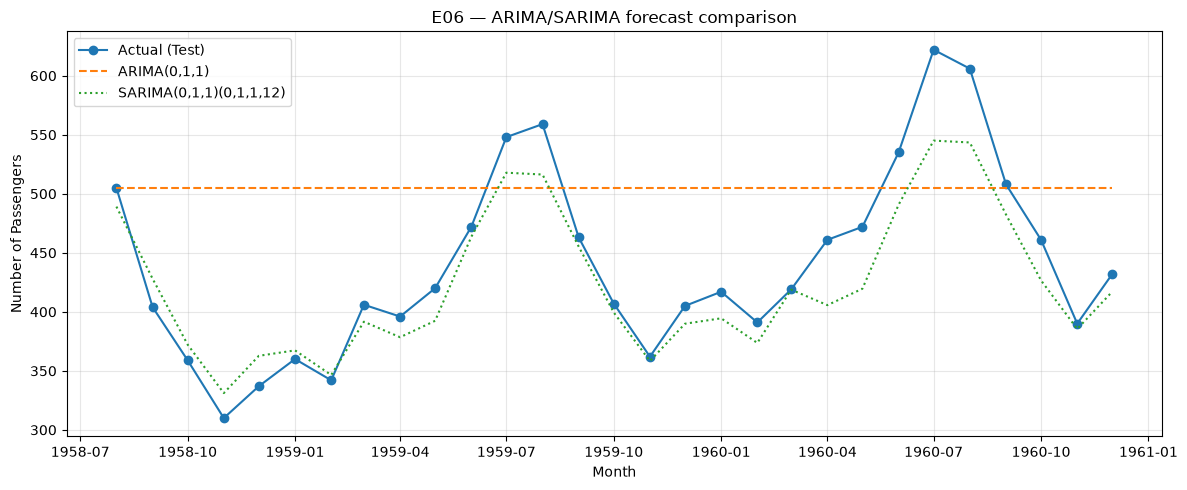

Model,MAE,RMSE,Status
"ARIMA(0,1,1)",88.42,101.10,Sealed 29-month holdout evaluation
"SARIMA(0,1,1)(0,1,1,12)",24.06,30.58,Sealed 29-month holdout evaluation


In [49]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

forecast_1 = arima_result.forecast(steps=len(test_series))
forecast_2 = sarima_result.forecast(steps=len(test_series))
mae_1 = mean_absolute_error(test_series, forecast_1)
rmse_1 = np.sqrt(mean_squared_error(test_series, forecast_1))
mae_2 = mean_absolute_error(test_series, forecast_2)
rmse_2 = np.sqrt(mean_squared_error(test_series, forecast_2))

evaluation = pd.DataFrame({
    "Model": [
        "ARIMA(0,1,1)",
        "SARIMA(0,1,1)(0,1,1,12)"
    ],
    "MAE": [mae_1, mae_2],
    "RMSE": [rmse_1, rmse_2],
    "Status": "Sealed 29-month holdout evaluation",
})
forecast_figure, forecast_axis = plt.subplots(figsize=(12, 5))
forecast_axis.plot(test_series.index, test_series.values, label="Actual (Test)", marker="o")
forecast_axis.plot(forecast_1.index, forecast_1.values, label="ARIMA(0,1,1)", linestyle="--")
forecast_axis.plot(forecast_2.index, forecast_2.values, label="SARIMA(0,1,1)(0,1,1,12)", linestyle=":")
forecast_axis.set_title("E06 — ARIMA/SARIMA forecast comparison")
forecast_axis.set_xlabel("Month")
forecast_axis.set_ylabel("Number of Passengers")
forecast_axis.legend()
forecast_axis.grid(True, alpha=0.3)
forecast_figure.tight_layout()
forecast_figure.savefig(FIGURES_DIR / "06_airpassengers_forecast_comparison.png", dpi=160, bbox_inches="tight")
plt.show()
display(style_table(
    evaluation,
    caption="E06 — Holdout metrics on the 29-month test set",
    formats={"MAE": "{:.2f}", "RMSE": "{:.2f}"},
    row_highlighter=highlight_exploratory,
))


### 10. Residual diagnostics

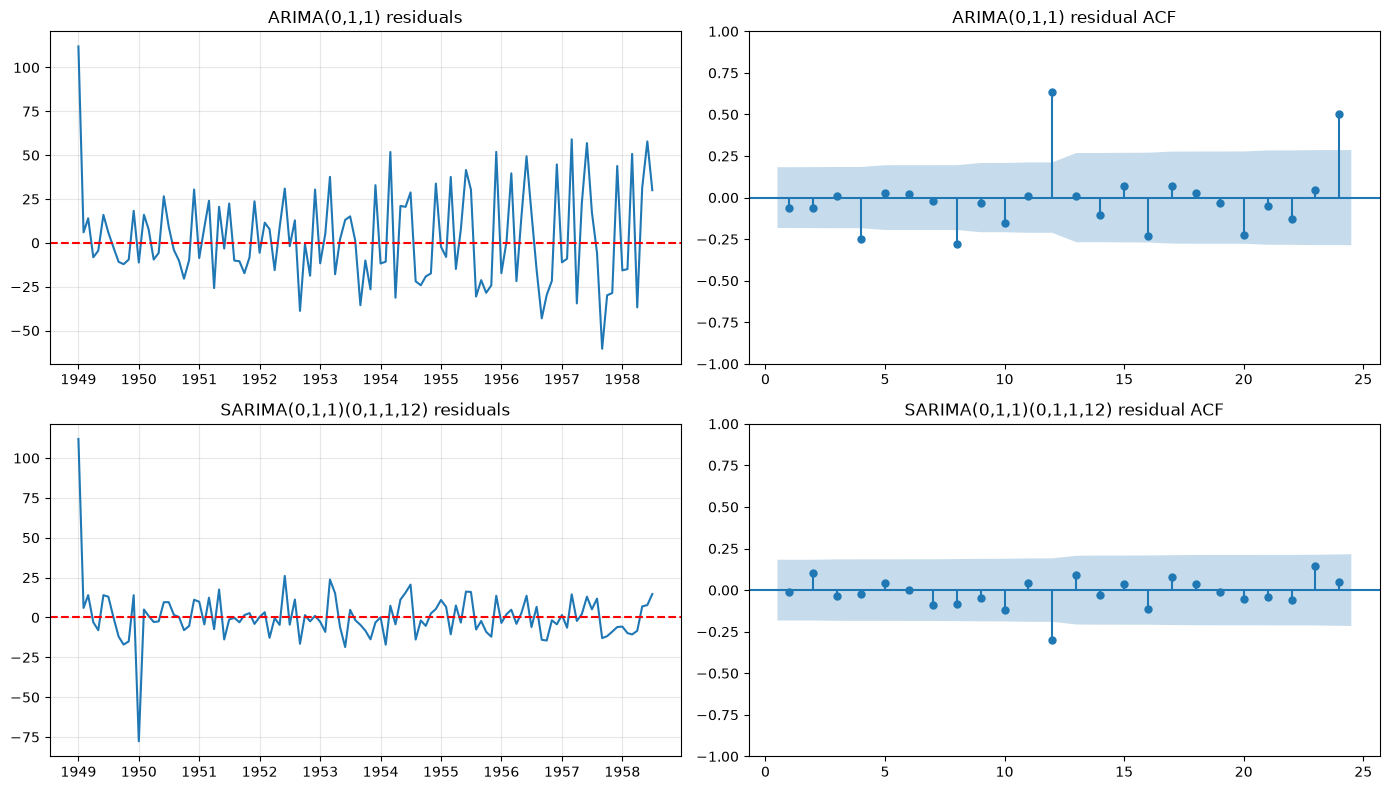

Model,Lag,Ljung-Box statistic,p-value,Interpretation
"ARIMA(0,1,1)",12,74.202,0.0000,Autocorrelation evidence remains
"ARIMA(0,1,1)",24,131.904,0.0000,Autocorrelation evidence remains
"SARIMA(0,1,1)(0,1,1,12)",12,17.845,0.1205,No rejection at selected lag
"SARIMA(0,1,1)(0,1,1,12)",24,26.456,0.3304,No rejection at selected lag


In [50]:
from statsmodels.stats.diagnostic import acorr_ljungbox

ALPHA = 0.05
diagnostic_rows = []
fig, axes = plt.subplots(len(model_results), 2, figsize=(14, 8))

for row_index, (model_name, fitted_model) in enumerate(model_results.items()):
    residuals = fitted_model.resid.dropna()
    axes[row_index, 0].plot(residuals.index, residuals.values)
    axes[row_index, 0].axhline(0, color="red", linestyle="--")
    axes[row_index, 0].set_title(f"{model_name} residuals")
    axes[row_index, 0].grid(True, alpha=0.3)
    plot_acf(residuals, lags=24, zero=False, ax=axes[row_index, 1])
    axes[row_index, 1].set_title(f"{model_name} residual ACF")
    ljung_box = acorr_ljungbox(residuals, lags=[12, 24], return_df=True)
    for lag, result in ljung_box.iterrows():
        diagnostic_rows.append({
            "Model": model_name,
            "Lag": int(lag),
            "Ljung-Box statistic": result["lb_stat"],
            "p-value": result["lb_pvalue"],
            "Interpretation": (
                "No rejection at selected lag"
                if result["lb_pvalue"] > ALPHA
                else "Autocorrelation evidence remains"
            ),
        })

plt.tight_layout()
fig.savefig(FIGURES_DIR / "06_airpassengers_residual_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

residual_diagnostics = pd.DataFrame(diagnostic_rows)
display(style_table(
    residual_diagnostics,
    caption="E06 — Residual Ljung–Box diagnostics",
    formats={"Ljung-Box statistic": "{:.3f}", "p-value": "{:.4f}"},
    row_highlighter=highlight_exploratory,
))


### 11. Save run artifacts

In [51]:
import logging
import os
from datetime import datetime

run_id = os.getenv("PRACTICE_2_RUN_ID", datetime.now().strftime("%Y-%m-%d_e06_%H%M%S"))
run_dir = PROJECT_ROOT / "runs" / run_id
results_dir = PROJECT_ROOT / "outputs" / "results"
evidence_path = PROJECT_ROOT / "docs" / "logs" / "exercise_06_execution.md"
run_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)
evidence_path.parent.mkdir(parents=True, exist_ok=True)

log_path = run_dir / "Practice_2_Advanced.log"
logger = logging.getLogger("practice_2_e06")
logger.handlers.clear()
logger.setLevel(logging.INFO)
file_handler = logging.FileHandler(log_path, mode="w", encoding="utf-8")
file_handler.setFormatter(logging.Formatter("%(asctime)s | %(levelname)s | %(message)s"))
logger.addHandler(file_handler)

import hashlib

if not forecast_1.index.equals(test_series.index) or not forecast_2.index.equals(test_series.index):
    raise ValueError("Forecast index does not align with the sealed 29-month test index.")

raw_sha256 = hashlib.sha256(RAW_PATH.read_bytes()).hexdigest()
split_path = results_dir / "06_airpassengers_split.csv"
adf_path = results_dir / "06_airpassengers_adf_results.csv"
candidates_path = results_dir / "06_airpassengers_model_candidates.csv"
diagnostics_path = results_dir / "06_airpassengers_model_diagnostics.csv"
forecasts_path = results_dir / "06_airpassengers_forecasts.csv"
metrics_path = results_dir / "06_airpassengers_metrics.csv"
validation_path = results_dir / "06_airpassengers_validation.csv"

adf_results = pd.concat([adf_table, adf_diff_table], ignore_index=True)
model_candidates = pd.DataFrame({
    "Model": ["ARIMA(0,1,1)", "SARIMA(0,1,1)(0,1,1,12)"],
    "Order": ["(0,1,1)", "(0,1,1)"],
    "Seasonal order": ["(0,0,0,0)", "(0,1,1,12)"],
    "AIC": [model_results["ARIMA(0,1,1)"].aic, model_results["SARIMA(0,1,1)(0,1,1,12)"].aic],
    "BIC": [model_results["ARIMA(0,1,1)"].bic, model_results["SARIMA(0,1,1)(0,1,1,12)"].bic],
    "Converged": [bool(model_results["ARIMA(0,1,1)"].mle_retvals.get("converged", False)), bool(model_results["SARIMA(0,1,1)(0,1,1,12)"].mle_retvals.get("converged", False))],
    "Rationale": [
        "Non-seasonal baseline for comparison",
        "Seasonal extension supported by s=12 and transformed-training ACF/PACF",
    ],
    "Status": "Fit on training series only",
})
forecast_table = pd.DataFrame({
    "Month": test_series.index,
    "Actual": test_series.to_numpy(),
    "ARIMA(0,1,1)": forecast_1.to_numpy(),
    "SARIMA(0,1,1)(0,1,1,12)": forecast_2.to_numpy(),
})
validation_summary = pd.DataFrame({
    "Check": [
        "Raw SHA-256",
        "Rows",
        "Missing target values",
        "Duplicate timestamps",
        "Monthly frequency",
        "Train observations",
        "Test observations",
        "Forecast index aligned",
        "Selected d",
        "Selected D",
        "Seasonal period",
    ],
    "Value": [
        raw_sha256,
        len(series),
        int(series.isna().sum()),
        int(series.index.duplicated().sum()),
        series.index.freqstr,
        len(train_series),
        len(test_series),
        True,
        selected_d,
        selected_D,
        SEASONAL_PERIOD,
    ],
})

split_summary.to_csv(split_path, index=False)
adf_results.to_csv(adf_path, index=False)
model_candidates.to_csv(candidates_path, index=False)
residual_diagnostics.to_csv(diagnostics_path, index=False)
forecast_table.to_csv(forecasts_path, index=False)
evaluation.to_csv(metrics_path, index=False)
validation_summary.to_csv(validation_path, index=False)

logger.info("Run ID: %s", run_id)
logger.info("Train observations: %s; test observations: %s", len(train_series), len(test_series))
logger.info("Raw SHA-256: %s", raw_sha256)
logger.info("ADF results:\n%s", adf_results.to_string(index=False))
logger.info("Model candidates:\n%s", model_candidates.to_string(index=False))
logger.info("Model metrics:\n%s", evaluation.to_string(index=False))
logger.info("Residual diagnostics:\n%s", residual_diagnostics.to_string(index=False))

evidence_text = "\n".join([
    "# E06 execution evidence",
    "",
    f"- Run ID: `{run_id}`",
    f"- Train/test boundary: {len(train_series)} / {len(test_series)} monthly observations",
    f"- Raw SHA-256: `{raw_sha256}`",
    f"- Selected differencing: d={selected_d}, D={selected_D}, s={SEASONAL_PERIOD}",
    "- Models: ARIMA(0,1,1) and SARIMA(0,1,1)(0,1,1,12)",
    f"- Raw runtime log: `runs/{run_id}/Practice_2_Advanced.log`",
    "- Forecast horizon: 29 monthly observations; forecast index aligned with test index",
    "",
    "## Artifact paths",
    f"- Validation: `{validation_path.relative_to(PROJECT_ROOT)}`",
    f"- Split: `{split_path.relative_to(PROJECT_ROOT)}`",
    f"- ADF: `{adf_path.relative_to(PROJECT_ROOT)}`",
    f"- Candidates: `{candidates_path.relative_to(PROJECT_ROOT)}`",
    f"- Diagnostics: `{diagnostics_path.relative_to(PROJECT_ROOT)}`",
    f"- Forecasts: `{forecasts_path.relative_to(PROJECT_ROOT)}`",
    f"- Metrics: `{metrics_path.relative_to(PROJECT_ROOT)}`",
    "",
    "## Holdout metrics",
    "```text",
    evaluation.to_string(index=False),
    "```",
    "",
    "## Ljung–Box diagnostics",
    "```text",
    residual_diagnostics.to_string(index=False),
    "```",
])
evidence_path.write_text(evidence_text + "\n", encoding="utf-8")

print(f"Run log: {log_path}")
print(f"Metrics: {metrics_path}")
print(f"Diagnostics: {diagnostics_path}")
print(f"Execution evidence: {evidence_path}")


Run log: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/runs/2026-11-27_e06_113951/Practice_2_Advanced.log
Metrics: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/outputs/results/06_airpassengers_metrics.csv
Diagnostics: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/outputs/results/06_airpassengers_model_diagnostics.csv
Execution evidence: /Users/vientu/Time Series/TOTAL_LAB_PRACTICE_FOR_TIME_SERIES/total_practice/Practice_2/docs/logs/exercise_06_execution.md


E06 là advanced extension độc lập. Chỉ rút ra kết luận sau khi notebook được chạy từ kernel sạch, residual diagnostics được kiểm tra và các artifact từ run thực tế đã được lưu.